# 8. Literatura y fundamentos del diseño

La síntesis se concentra en pronóstico de demanda e integración documental. Se consultan textos completos para distinguir resultados, arquitecturas y condiciones de transferencia al SIN. El país de afiliación se separa del sistema eléctrico analizado.

## Estudios de mayor pertinencia

| Estudio | Afiliación / datos | Modelo o enfoque | Resultados y pertinencia |
|---|---|---|---|
| [Nti et al. (2020), Electricity load forecasting: a systematic review](https://doi.org/10.1186/s43067-020-00021-8) | Ghana / múltiples países | Revisión de métodos estadísticos y de inteligencia artificial | Identifica clima, calendario y actividad socioeconómica como factores relevantes. La heterogeneidad de datos y horizontes impide trasladar un ranking único al SIN. |
| [Bai, Camal y Michiorri, News and Load (versión 2024)](https://arxiv.org/abs/2301.07535) | Francia / Gran Bretaña e Irlanda del Norte | ExtraTrees con demanda, calendario, temperatura y atributos de noticias | Algunas representaciones y conjuntos de noticias mejoran la referencia; no todas las fuentes o combinaciones son útiles. Motiva contrastar el aporte textual con una referencia numérica estable. |
| [Bai, Camal y Michiorri (2023), Electricity Demand Forecasting through Natural Language Processing with Long Short-Term Memory Networks](https://arxiv.org/abs/2309.06793) | Francia / Reino Unido | LSTM y autoencoder CNN para comprimir atributos textuales | La representación y compresión afectan el desempeño. Añadir todas las representaciones puede deteriorarlo; aporta un diseño de ablación y extensión probabilística. |

Los trabajos de Bai y colaboradores comparten una línea de investigación y referencias experimentales; no son replicaciones independientes en Colombia. La síntesis dirigida no equivale a una revisión sistemática ni permite calcular frecuencias representativas de arquitecturas.

## Representación textual y desempeño

La tabla I del estudio LSTM permite comparar variantes con la misma referencia numérica. S representa sentimiento; G, GloVe; CG, GloVe comprimido mediante autoencoder CNN; W, frecuencias de palabras; T, tópicos.

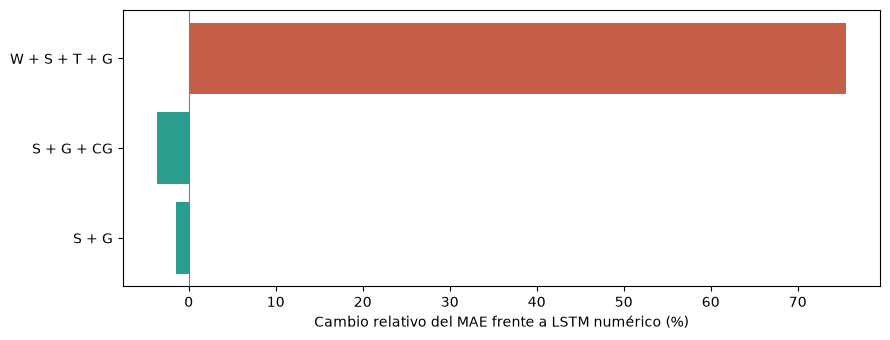

In [1]:
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
# MAE de la tabla I del texto completo, arXiv:2309.06793.
mae_lstm=2333.20
variantes={'S + G':2299.20,'S + G + CG':2248.55,'W + S + T + G':4094.80}
cambios={nombre:100*(valor/mae_lstm-1) for nombre,valor in variantes.items()}
fig,ax=plt.subplots(figsize=(9,3.5))
ax.barh(list(cambios),list(cambios.values()),color=['#2a9d8f' if v<0 else '#c65d47' for v in cambios.values()])
ax.axvline(0,color='grey',lw=.8); ax.set_xlabel('Cambio relativo del MAE frente a LSTM numérico (%)')
fig.tight_layout(); display(fig); plt.close(fig)
mejora_cg=-cambios['S + G + CG']; deterioro_total=cambios['W + S + T + G']


S + G + CG reduce el MAE un 3.63 %, mientras W + S + T + G lo incrementa un 75.50 %. La utilidad depende de la representación y su selección; los valores pertenecen al experimento británico y no estiman la mejora esperable en el SIN. [Fuente: tabla I del artículo](https://arxiv.org/html/2309.06793).

## Implicaciones para el diseño

La memoria diaria y semanal, el calendario y los cambios de nivel orientan la representación temporal. Una referencia lineal cuantifica cuánto resuelve una combinación aditiva de rezagos; una red de alimentación directa representa interacciones no lineales; una arquitectura recurrente contrasta el procesamiento secuencial de la historia. La selección final y sus resultados se desarrollarán en el capítulo de modelos.

Clima e hidrología se consideran mediante ablaciones con los mismos orígenes y presupuesto. Para el texto se congela cada representación tras ajustarla en entrenamiento y se comparan escenarios de disponibilidad. Los tópicos exploratorios no se convierten en categorías manuales.

[Hyndman y Athanasopoulos, Forecasting: Principles and Practice](https://otexts.com/fpp3/toolbox.html) sustentan las referencias estacionales, los errores escalados y la evaluación temporal. La comparación se realiza sobre los mismos orígenes y se complementa con errores en la escala original.

## Comparación de arquitecturas para demanda nacional

[Pelekis et al. (2023), *A comparative assessment of deep learning models for day-ahead load forecasting: Investigating key accuracy drivers*](https://arxiv.org/abs/2302.12168), con afiliación en Grecia, estudian demanda nacional portuguesa horaria de 2013–2021. Comparan MLP, LSTM, N-BEATS, TCN y TFT con referencias estacionales. La tabla 4 separa versiones univariantes y extensiones con temperatura ex-post de Lisboa.

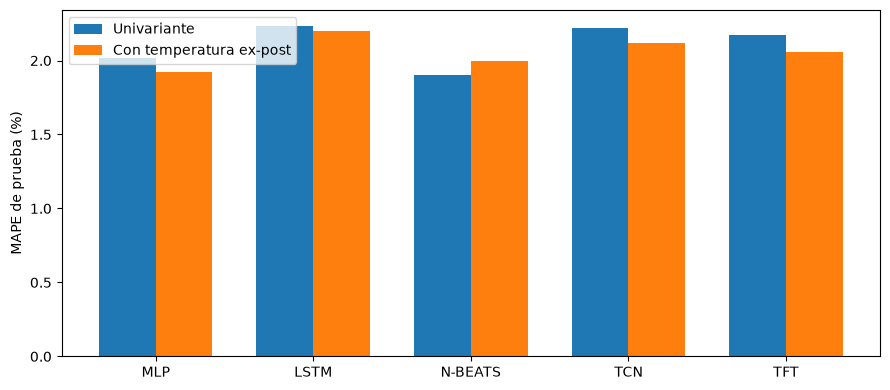

In [2]:
# Tabla 4 del texto completo, arXiv:2302.12168v2.
arquitecturas=['MLP','LSTM','N-BEATS','TCN','TFT']
univar=np.array([2.02,2.23,1.90,2.22,2.17])
temp_expost=np.array([1.92,2.20,2.00,2.12,2.06])
pos=np.arange(len(arquitecturas))
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(pos-.18,univar,width=.36,label='Univariante')
ax.bar(pos+.18,temp_expost,width=.36,label='Con temperatura ex-post')
ax.set(xticks=pos,xticklabels=arquitecturas,ylabel='MAPE de prueba (%)'); ax.legend()
fig.tight_layout(); display(fig); plt.close(fig)
ganancia_mlp=float(100*(1-temp_expost[0]/univar[0]))


N-BEATS univariante presenta el menor MAPE de esta comparación; MLP mejora un 4.95 % relativo con temperatura ex-post. Una arquitectura más compleja no garantiza menor error y la temperatura no beneficia a todas. La extensión ex-post no demuestra disponibilidad meteorológica operativa. [Fuente: tabla 4](https://arxiv.org/html/2302.12168).

## Criterios de extracción y justificación de familias

| Familia | Evidencia y función en el estudio | Aspecto a contrastar |
|---|---|---|
| Regresión autorregresiva con entradas externas | La revisión de Nti et al. sitúa métodos estadísticos y regresión entre las referencias de demanda. La versión penalizada del protocolo ofrece una comparación aditiva de baja complejidad. | Utilidad de memoria y calendario sin interacciones no lineales. |
| MLP | Pelekis et al. la comparan directamente con arquitecturas más complejas en demanda nacional. | Si las interacciones de una ventana aplanada bastan para representar la señal. |
| LSTM | Aparece en Pelekis et al. y en el trabajo de Bai et al. con texto. | Si procesar secuencialmente la historia aporta frente a una representación densa. |

La revisión no establece que la regresión penalizada exacta del protocolo sea la más frecuente ni que estas tres familias sean universalmente superiores. N-BEATS, TCN, TFT y compresión textual constituyen arquitecturas de interés para ampliaciones; no modifican el presupuesto ni los modelos que ya están en entrenamiento.

## Registro de la evidencia

La extracción conserva título, identificador DOI o arXiv, versión, país de afiliación, sistema eléctrico, frecuencia, horizonte, entradas, comparadores y localización del resultado. Las cifras de artículos se reproducen mediante celdas visibles y se distinguen de resultados del SIN. La calidad de transferencia se valora por similitud del objetivo, separación cronológica, disponibilidad de covariables y tratamiento de semillas. La selección dirigida no permite construir un flujo PRISMA ni una frecuencia exhaustiva de modelos; eso requiere búsquedas y criterios documentados sobre un inventario más amplio.

## Correspondencia con el benchmark ejecutado

El benchmark neuronal se integra por MLP, LSTM y CNN1D; ARX es una referencia lineal de contexto. MLP y LSTM tienen comparaciones directas de demanda en los estudios examinados. La familia convolucional se relaciona con filtros temporales y las comparaciones de TCN de Pelekis et al.; la CNN poco profunda implementada se especificó en PREREGISTRO_CNN1D.md y no se presenta como réplica exacta de una TCN ni del autoencoder textual de Bai et al. La síntesis dirigida no demuestra una frecuencia exhaustiva de uso de las tres arquitecturas.